# Extension B1: A simulated coupon experiment with five arms

The main email case had cheap emails and two treatments. Many modern experiments look different: a food-delivery app tests **several coupon levels at once**, outcomes run through a **funnel** (see the offer → click → order), and every coupon **costs money** on each order it touches, including orders that would have happened anyway.

There is no public dataset of that kind with defined metrics and costs (see [why this dataset](../CASE_STUDY.md#why-this-dataset)), so this lesson uses a **simulation**, loosely modelled on large-scale coupon tests such as Meituan's MT-LIFT. The big advantage: because we set the rules of the simulated world, we know the **true** effect of every coupon and can check every method against it.

**The simulated experiment:**

| Item | Value |
|---|---|
| Arms | No coupon, ¥3, ¥5, ¥8, ¥12 off |
| Users | 200,000 per arm (1 million in total), randomly assigned |
| Funnel | Offer shown → click → order |
| Platform economics | 20% commission on an average ¥52 order; the platform pays 50% of the coupon, merchants the rest |
| Hidden traits | Each user's purchase intent and whether they are price-sensitive |
| Observable features | Past orders, past coupon redemptions, new user, city tier |

In [1]:
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from expt.inference import compare_means, compare_proportions, holm, ratio_delta_method
from expt.plotting import INK, INK_2, SERIES, new_figure, style_axes
from expt.policy import policy_value
from expt.simulate import CouponWorld, outcome_probabilities, simulate_experiment, true_arm_values
from expt.uplift import t_learner

world = CouponWorld()
sim = simulate_experiment(n_per_arm=200_000, world=world, seed=2026)
truth = true_arm_values(sim, world)
COUPONS = list(world.coupon_values)
LABELS = ["No coupon"] + [f"¥{v:.0f}" for v in COUPONS[1:]]
print(sim.groupby("level").size().rename(index=dict(enumerate(LABELS))).to_dict())

{'No coupon': 200000, '¥3': 200000, '¥5': 200000, '¥8': 200000, '¥12': 200000}


## 1. The truth (normally hidden)

In a real experiment nobody knows this table; the experiment exists to estimate it. Here we can look first, then see how close the analysis gets.

In [2]:
shown = truth.copy()
shown.index = LABELS
shown["profit change vs no coupon"] = shown["profit_per_user"] - shown["profit_per_user"].iloc[0]
shown.style.format({"coupon": "¥{:.0f}", "click_rate": "{:.2%}", "order_rate": "{:.2%}", "orders_per_click": "{:.2%}",
                    "profit_per_user": "¥{:.4f}", "profit change vs no coupon": "¥{:+.4f}"})

,coupon,click_rate,order_rate,orders_per_click,profit_per_user,profit change vs no coupon
No coupon,¥0,24.36%,4.86%,19.93%,¥0.5050,¥+0.0000
¥3,¥3,31.01%,6.06%,19.55%,¥0.5396,¥+0.0346
¥5,¥5,34.32%,6.64%,19.35%,¥0.5248,¥+0.0198
¥8,¥8,38.24%,7.31%,19.12%,¥0.4678,¥-0.0372
¥12,¥12,42.14%,7.96%,18.88%,¥0.3501,¥-0.1549


Bigger coupons always bring more orders, but the ¥3 coupon earns the most profit, and the ¥12 coupon loses money even though it brings the most orders. The question is whether the experiment can see that.

## 2. Orders: each coupon against no coupon

Four comparisons against one control, so the p-values are adjusted with Holm (as in chapter 4a).

In [3]:
control = sim[sim["level"] == 0]
rows = []
for level in range(1, 5):
    t = sim[sim["level"] == level]
    r = compare_proportions(t["order"].sum(), len(t), control["order"].sum(), len(control))
    true_lift = truth.loc[level, "order_rate"] / truth.loc[0, "order_rate"] - 1
    rows.append({"coupon": LABELS[level], "order rate": r.rate_treatment, "lift": r.lift, "lift low": r.lift_low,
                 "lift high": r.lift_high, "true lift": true_lift, "p_value": r.p_value})
orders = pd.DataFrame(rows).set_index("coupon")
orders["p_holm"] = holm(orders["p_value"])
orders.style.format({"order rate": "{:.2%}", "lift": "{:+.1%}", "lift low": "{:+.1%}", "lift high": "{:+.1%}",
                     "true lift": "{:+.1%}", "p_value": "{:.1e}", "p_holm": "{:.1e}"})

,order rate,lift,lift low,lift high,true lift,p_value,p_holm
coupon,,,,,,,
¥3,6.05%,+24.1%,+20.9%,+27.3%,+24.9%,6.4e-60,6.4e-60
¥5,6.69%,+37.1%,+33.6%,+40.6%,+36.8%,1.6e-132,3.3e-132
¥8,7.29%,+49.4%,+45.8%,+53.2%,+50.5%,2.4e-223,7.3e-223
¥12,7.87%,+61.3%,+57.4%,+65.3%,+63.9%,0.0e+00,0.0e+00


Every coupon lifts orders, the lift grows with the coupon (a **dose-response**), and each interval contains the true lift. On orders alone, the ¥12 coupon looks best.

## 3. The ratio trap: orders per click

A common dashboard metric is the conversion rate *after* the click: orders per click. Computed per arm, with a delta-method standard error (the click count is random too):

In [4]:
rows = []
r_c, se_c = ratio_delta_method(control["order"], control["click"])
for level in range(5):
    g = sim[sim["level"] == level]
    r, se = ratio_delta_method(g["order"], g["click"])
    rows.append({"coupon": LABELS[level], "clicks per user": g["click"].mean(), "orders per click": r,
                 "change vs no coupon": r - r_c, "95% CI": f"{r - r_c - 1.96 * np.hypot(se, se_c):+.2%} to {r - r_c + 1.96 * np.hypot(se, se_c):+.2%}" if level else "",
                 "true orders per click": truth.loc[level, "orders_per_click"]})
pd.DataFrame(rows).set_index("coupon").style.format({"clicks per user": "{:.1%}", "orders per click": "{:.2%}",
                                                      "change vs no coupon": "{:+.2%}", "true orders per click": "{:.2%}"})

,clicks per user,orders per click,change vs no coupon,95% CI,true orders per click
coupon,,,,,
No coupon,24.4%,20.00%,+0.00%,,19.93%
¥3,31.0%,19.53%,-0.48%,-0.95% to -0.00%,19.55%
¥5,34.3%,19.49%,-0.51%,-0.97% to -0.05%,19.35%
¥8,38.3%,19.06%,-0.95%,-1.40% to -0.50%,19.12%
¥12,41.9%,18.79%,-1.21%,-1.65% to -0.77%,18.88%


Orders per click **fall** as the coupon grows, significantly for the large coupons, while orders per user **rise**. A team watching the post-click conversion rate would conclude that big coupons "hurt conversion".

The mechanism is the one from chapter 4a: coupons draw in extra clickers who are less ready to buy than the users who would have clicked anyway. The set of clickers changes, so orders per click compares different people. In the simulation we can see it directly: coupon-induced clicks come disproportionately from low-intent users. **Judge a coupon on outcomes per user assigned, never per click.**

## 4. Profit: the metric that matters

In [5]:
rows = []
for level in range(1, 5):
    t = sim[sim["level"] == level]
    r = compare_means(t["profit"], control["profit"])
    rows.append({"coupon": LABELS[level], "profit change": r.diff, "low": r.diff_low, "high": r.diff_high,
                 "true change": truth.loc[level, "profit_per_user"] - truth.loc[0, "profit_per_user"], "p_value": r.p_value})
profit = pd.DataFrame(rows).set_index("coupon")
profit["p_holm"] = holm(profit["p_value"])
profit["p_dunnett"] = stats.dunnett(*[sim.loc[sim["level"] == lv, "profit"].to_numpy() for lv in range(1, 5)],
                                    control=control["profit"].to_numpy()).pvalue
profit.style.format({"profit change": "¥{:+.4f}", "low": "¥{:+.4f}", "high": "¥{:+.4f}", "true change": "¥{:+.4f}",
                     "p_value": "{:.1e}", "p_holm": "{:.1e}", "p_dunnett": "{:.1e}"})

,profit change,low,high,true change,p_value,p_holm,p_dunnett
coupon,,,,,,,
¥3,¥+0.0319,¥+0.0171,¥+0.0468,¥+0.0346,2.6e-05,5.2e-05,1.5e-05
¥5,¥+0.0265,¥+0.0119,¥+0.0411,¥+0.0198,3.7e-04,3.7e-04,4.5e-04
¥8,¥-0.0350,¥-0.0489,¥-0.0211,¥-0.0372,7.8e-07,2.3e-06,1.8e-06
¥12,¥-0.1507,¥-0.1637,¥-0.1377,¥-0.1549,1.0e-113,4.2e-113,0.0e+00


**Dunnett's test** is designed specifically for "several treatments vs one control"; it is a little less conservative than Holm because it accounts for all comparisons sharing the same control group. Here both agree.

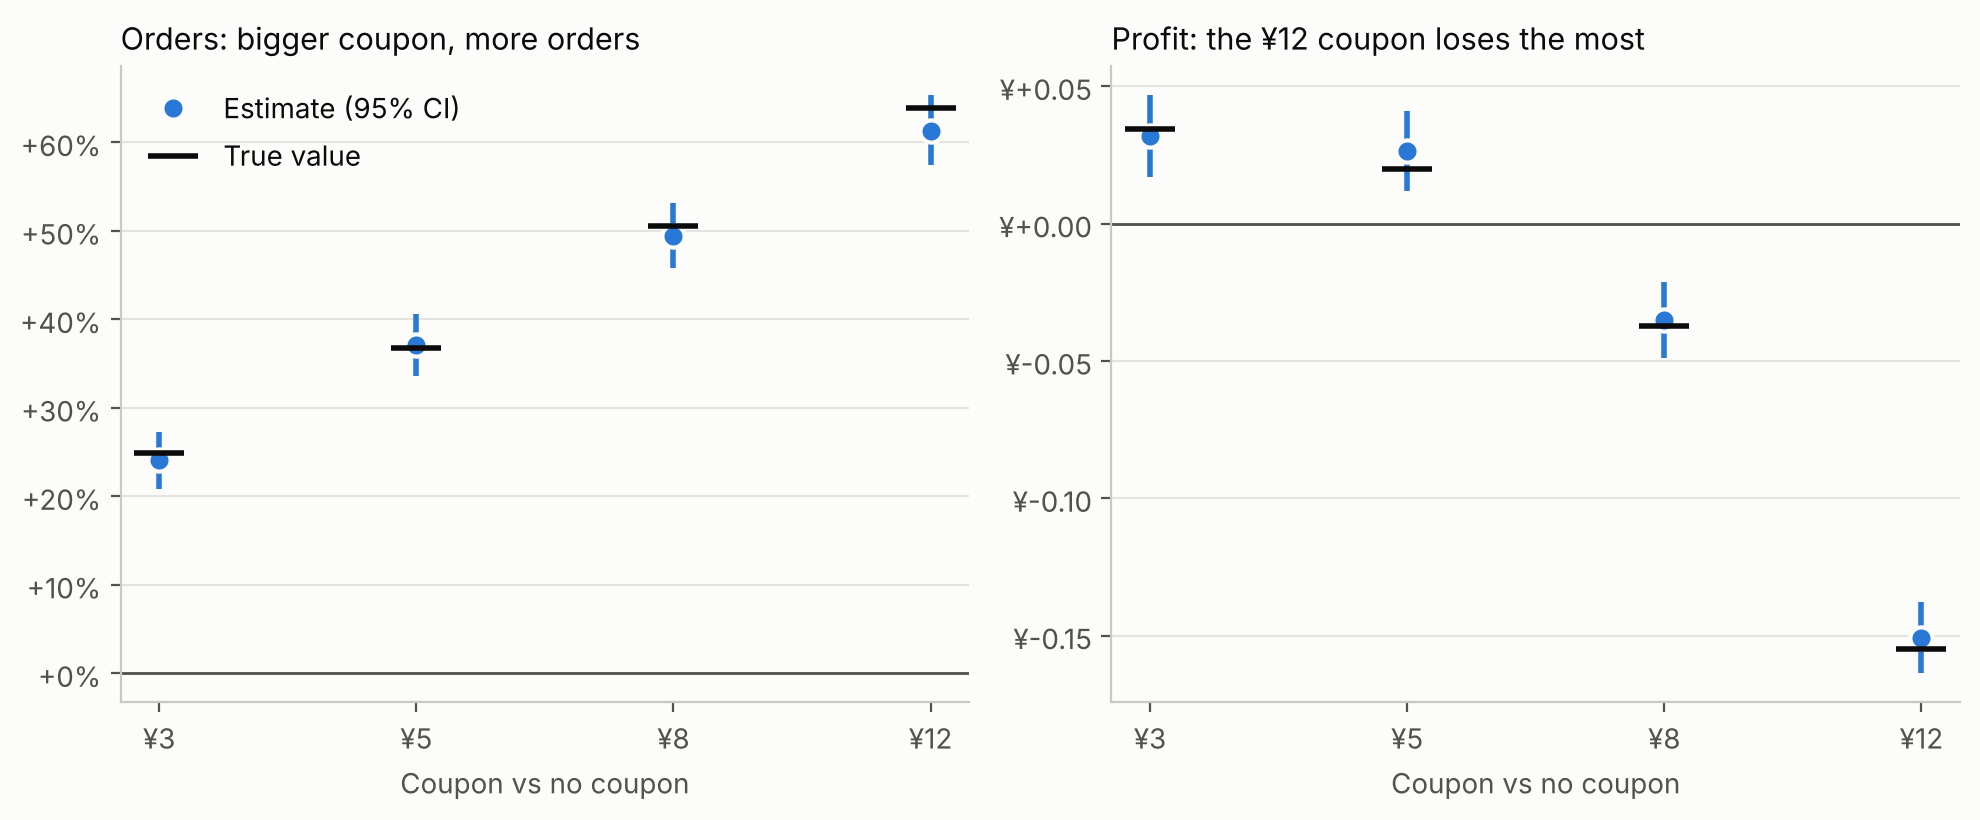

In [6]:
# figure: coupons_orders_vs_profit
fig, (ax1, ax2) = new_figure(10, 4.2, ncols=2)
x = np.arange(1, 5)
for ax, table, col, low, high, true, title, fmt in [
    (ax1, orders, "lift", "lift low", "lift high", "true lift", "Orders: bigger coupon, more orders", lambda v: f"{v:+.0%}"),
    (ax2, profit, "profit change", "low", "high", "true change", "Profit: the ¥12 coupon loses the most", lambda v: f"¥{v:+.2f}"),
]:
    ax.vlines(x, table[low], table[high], color=SERIES[0], linewidth=2)
    ax.plot(x, table[col], "o", color=SERIES[0], markersize=8, markeredgecolor="#fcfcfb", markeredgewidth=1.5, label="Estimate (95% CI)")
    ax.plot(x, table[true], "_", color=INK, markersize=18, markeredgewidth=2, label="True value")
    ax.axhline(0, color=INK_2, linewidth=1)
    ax.set_xticks(x, LABELS[1:])
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _, f=fmt: f(v)))
    style_axes(ax, title=title, xlabel="Coupon vs no coupon")
ax1.legend(frameon=False, loc="upper left", labelcolor=INK)
plt.tight_layout()
plt.show()

**The coupon that maximises orders is the one that loses the most money.** Every coupon is paid on all orders that use it, including the many that would have happened without it. A team with "orders" as its primary metric would roll out the ¥12 coupon and lose about ¥0.15 per user compared with no coupon at all.

### Can the experiment separate ¥3 from ¥5?

In [7]:
r = compare_means(sim.loc[sim["level"] == 1, "profit"], sim.loc[sim["level"] == 2, "profit"])
true_diff = truth.loc[1, "profit_per_user"] - truth.loc[2, "profit_per_user"]
print(f"¥3 minus ¥5, profit per user: ¥{r.diff:+.4f} (95% CI ¥{r.diff_low:+.4f} to ¥{r.diff_high:+.4f}, p = {r.p_value:.2f}); truth ¥{true_diff:+.4f}")

¥3 minus ¥5, profit per user: ¥+0.0054 (95% CI ¥-0.0090 to ¥+0.0198, p = 0.46); truth ¥+0.0148


Not with 200,000 users per arm. The truth says ¥3 is better, but the difference is small relative to the noise in profit. In practice: choose ¥3 (cheaper, at least as good on the evidence) or run a focused follow-up between the two.

## 5. Who should get a coupon?

In the main case the email cost two cents, so sending it to everyone was best. Coupons are expensive, so targeting matters: in this world, coupons only pay off for **price-sensitive** users. Those are hidden, but the number of past coupons a user redeemed is a strong clue.

Compare targeting policies. Because this is a simulation, we can compute each policy's **true** profit exactly, alongside the inverse-propensity estimate a real analyst would see (chapter 5).

In [8]:
features = ["past_orders", "coupon_history", "new_user", "city_tier"]
test = np.random.default_rng(0).random(len(sim)) < 0.3
level = sim["level"].to_numpy()
X = sim[features]
make_model = lambda: lgb.LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=15, min_child_samples=500, verbose=-1)

predicted_gain = np.zeros((test.sum(), 5))
for lv in range(1, 5):
    train = (~test) & np.isin(level, [0, lv])
    predicted_gain[:, lv] = t_learner(X[train], sim.loc[train, "profit"].to_numpy(), (level[train] == lv).astype(int), X[test], make_model)

true_profit = np.column_stack([outcome_probabilities(sim, v, world)["expected_profit"] for v in COUPONS])[test]
n = test.sum()
policies = {
    "No coupon": np.zeros(n, int),
    "¥3 to everyone": np.full(n, 1),
    "¥5 to everyone": np.full(n, 2),
    "Rule: ¥5 if 3+ past coupons redeemed, else none": np.where(sim.loc[test, "coupon_history"].to_numpy() >= 3, 2, 0),
    "Uplift model (T-learner on profit)": predicted_gain.argmax(axis=1),
    "Oracle: true best coupon per user": true_profit.argmax(axis=1),
}
rows = []
for name, p in policies.items():
    rows.append({"policy": name,
                 "true profit per user": true_profit[np.arange(n), p].mean(),
                 "estimated (IPW)": policy_value(sim.loc[test, "profit"].to_numpy(), level[test], p, {lv: 0.2 for lv in range(5)}),
                 "share given a coupon": (p > 0).mean()})
targeting = pd.DataFrame(rows).set_index("policy")
targeting.style.format({"true profit per user": "¥{:.4f}", "estimated (IPW)": "¥{:.4f}", "share given a coupon": "{:.0%}"})

,true profit per user,estimated (IPW),share given a coupon
policy,,,
No coupon,¥0.5053,¥0.5109,0%
¥3 to everyone,¥0.5398,¥0.5337,100%
¥5 to everyone,¥0.5250,¥0.5400,100%
"Rule: ¥5 if 3+ past coupons redeemed, else none",¥0.5522,¥0.5494,39%
Uplift model (T-learner on profit),¥0.5353,¥0.5369,72%
Oracle: true best coupon per user,¥0.5630,¥0.5597,35%


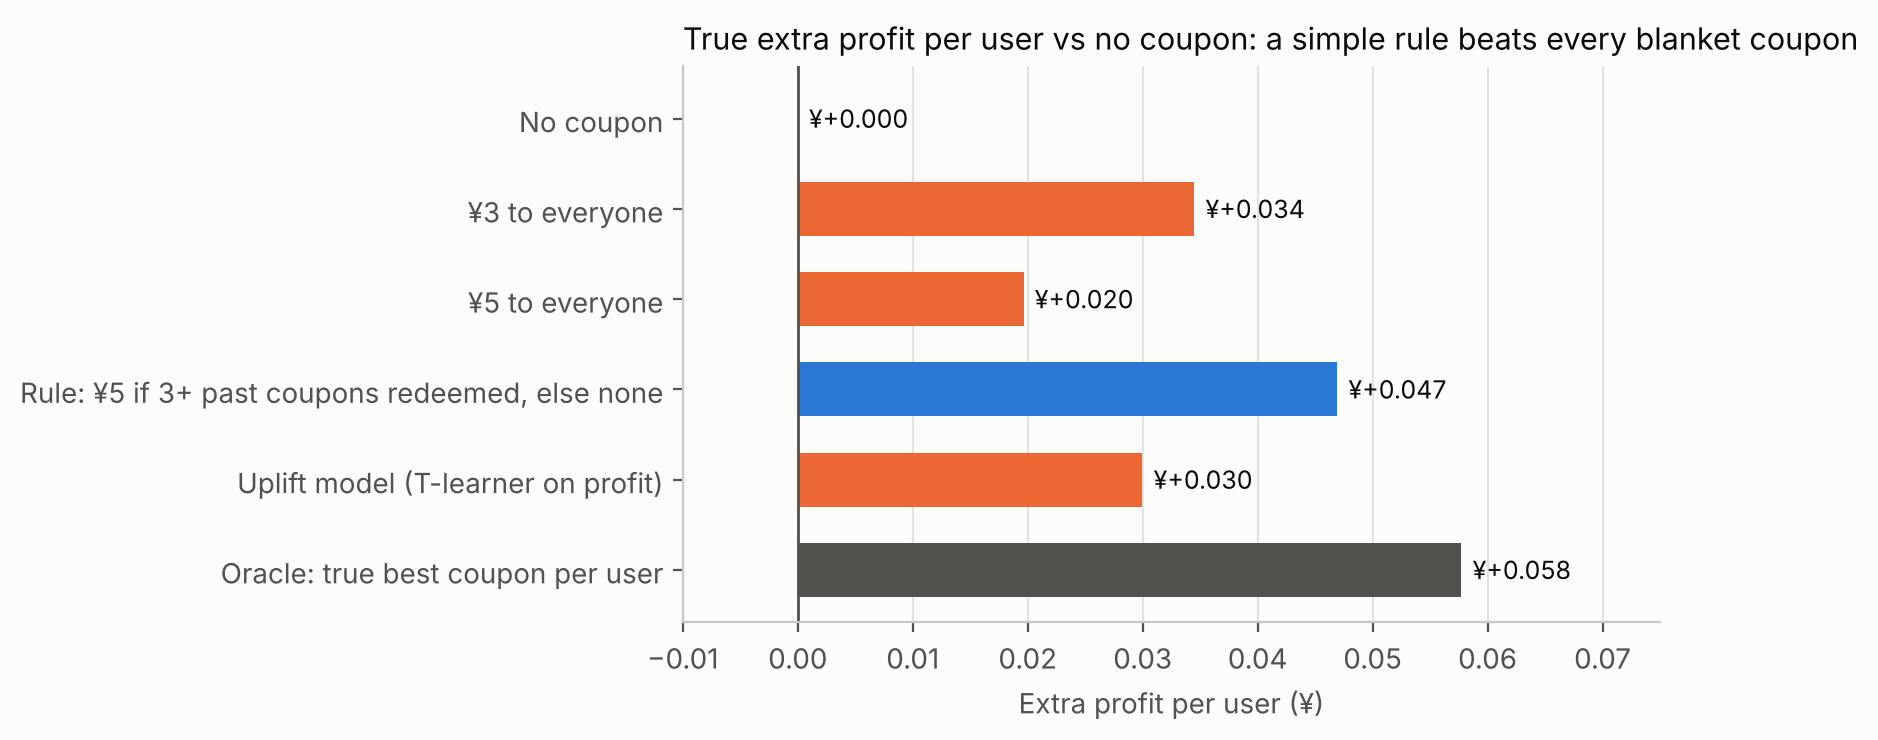

In [9]:
# figure: coupon_targeting
fig, ax = new_figure(8.5, 3.8)
names = list(targeting.index)[::-1]
base = targeting.loc["No coupon", "true profit per user"]
for i, name in enumerate(names):
    v = targeting.loc[name, "true profit per user"] - base
    color = SERIES[0] if name.startswith("Rule") else (INK_2 if name.startswith("Oracle") else SERIES[1])
    ax.barh(i, v, color=color, height=0.6)
    ax.annotate(f"¥{v:+.3f}", (v, i), xytext=(4 if v >= 0 else -4, 0), textcoords="offset points",
                ha="left" if v >= 0 else "right", va="center", color=INK, fontsize=9)
ax.axvline(0, color=INK_2, linewidth=1)
ax.set_yticks(range(len(names)), names)
ax.set_xlim(-0.01, 0.075)
style_axes(ax, title="True extra profit per user vs no coupon: a simple rule beats every blanket coupon",
           xlabel="Extra profit per user (¥)", grid="x")
plt.tight_layout()
plt.show()

- **The rule** (¥5 only for users who redeemed coupons before) beats every blanket coupon and captures most of the gain the oracle shows is possible, while giving coupons to well under half of users.
- **The uplift model** trained directly on profit does no better than a blanket ¥3: profit is too noisy a target for the model to find the price-sensitive users reliably, even with 700,000 training users.
- **The IPW estimates** are close to the true values, which is why the method is trusted for evaluating policies on randomised data.

## 6. Lessons

1. **Choose the metric that matches the business goal.** Orders favour the biggest coupon; profit favours the smallest.
2. **Never judge a funnel step on a conditional metric** such as orders per click.
3. **With several arms, adjust for multiple comparisons** (Holm or Dunnett) and expect that close arms may not be separable.
4. **When treatments are expensive, targeting pays**, and a rule with a reason can beat a model.

## Try it yourself

**a)** Set `platform_coupon_share=0.2` in `CouponWorld` (merchants pay 80% of each coupon) and rerun. Which coupon maximises profit now?

**b)** Rerun with `n_per_arm=50_000`. Which conclusions survive, and which comparisons stop being significant?

**c)** Train the uplift model on `order` instead of `profit`, then convert the predicted order lift into profit using the known margins. Does it beat the rule?